<a href="https://colab.research.google.com/github/oleg61/DataScient/blob/Learn_AI/%D0%92%D0%BE%D1%80%D0%BE%D0%BF%D0%B0%D0%B5%D0%B2_%D0%9E%D0%A1_%D0%9A%D0%BE%D0%BC%D0%BF%D1%8C%D1%8E%D1%82%D0%B5%D1%80%D0%BD%D0%BE%D0%B5_%D0%B7%D1%80%D0%B5%D0%BD%D0%B8%D0%B52.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ДЗ: Компьютерное зрение 2 — сегментация кружочков сетью U-Net

**Автор:** Воропаев О.С.

**Задание.** Обучить U-Net сегментировать сгенерированные кружочки. Код генерации данных — из `ДЗ_Лекция11.ipynb` (классический генератор «серых кружков» из туториалов по U-Net): на изображении 572×572 случайно размещается 20 кругов случайного радиуса (5–50 px) и яркости, поверх — гауссов шум; целевая маска — бинарная (круг/фон).

**Архитектура** — U-Net с занятия (Занятие 10: `DownConv`/`UpConv`, паддированные свёртки 3×3, skip-connections через конкатенацию, транспонированные свёртки). Модель предсказывает **для каждого пикселя** класс (фон/круг), лосс — перекрёстная энтропия, качество — IoU и Dice пиксельной маски.

**План:**

1. Взять генератор из `ДЗ_Лекция11.ipynb` и посмотреть на пары «картинка + маска».
2. Собрать U-Net как на занятии и обучить на бесконечном потоке сгенерированных пар.
3. Проверить качество на отложенной генерации (IoU/Dice) и визуально.


In [1]:
%matplotlib inline

## 1. Данные: генератор кружочков

Код генерации — из `ДЗ_Лекция11.ipynb`, изменено только одно: `np.bool` удалён из numpy (с версии 1.24), вместо него встроенный `bool`. Генератор при каждом вызове создаёт новую пару: зашумлённое изображение с кругами и бинарную маску. Классы возвращаются в one-hot виде `[..., 0]` = фон, `[..., 1]` = круг.


In [2]:
import numpy as np
from PIL import Image


class BaseDataProvider(object):
    channels = 1
    n_class = 2

    def __init__(self, a_min=None, a_max=None):
        self.a_min = a_min if a_min is not None else -np.inf
        self.a_max = a_max if a_min is not None else np.inf

    def _load_data_and_label(self):
        data, label = self._next_data()

        train_data = self._process_data(data)
        labels = self._process_labels(label)

        train_data, labels = self._post_process(train_data, labels)

        nx = train_data.shape[1]
        ny = train_data.shape[0]

        return train_data.reshape(1, ny, nx, self.channels), labels.reshape(1, ny, nx, self.n_class),

    def _process_labels(self, label):
        if self.n_class == 2:
            nx = label.shape[1]
            ny = label.shape[0]
            labels = np.zeros((ny, nx, self.n_class), dtype=np.float32)

            if label.dtype != 'bool':
                label = label.astype(bool)

            labels[..., 1] = label
            labels[..., 0] = ~label
            return labels

        return label

    def _process_data(self, data):
        # normalization
        data = np.clip(np.fabs(data), self.a_min, self.a_max)
        data -= np.amin(data)

        if np.amax(data) != 0:
            data /= np.amax(data)

        return data

    def _post_process(self, data, labels):
        return data, labels

    def __call__(self, n):
        train_data, labels = self._load_data_and_label()
        nx = train_data.shape[1]
        ny = train_data.shape[2]

        X = np.zeros((n, nx, ny, self.channels))
        Y = np.zeros((n, nx, ny, self.n_class))

        X[0] = train_data
        Y[0] = labels
        for i in range(1, n):
            train_data, labels = self._load_data_and_label()
            X[i] = train_data
            Y[i] = labels

        return X, Y


class GrayScaleDataProvider(BaseDataProvider):
    channels = 1
    n_class = 2

    def __init__(self, nx, ny, **kwargs):
        super(GrayScaleDataProvider, self).__init__()
        self.nx = nx
        self.ny = ny
        self.kwargs = kwargs
        rect = kwargs.get("rectangles", False)
        if rect:
            self.n_class = 3

    def _next_data(self):
        return create_image_and_label(self.nx, self.ny, **self.kwargs)


def create_image_and_label(nx, ny, cnt=10, r_min=5, r_max=50, border=92, sigma=20, rectangles=False):
    image = np.ones((nx, ny, 1))
    label = np.zeros((nx, ny, 3), dtype=bool)
    mask = np.zeros((nx, ny), dtype=bool)
    for _ in range(cnt):
        a = np.random.randint(border, nx - border)
        b = np.random.randint(border, ny - border)
        r = np.random.randint(r_min, r_max)
        h = np.random.randint(1, 255)

        y, x = np.ogrid[-a:nx - a, -b:ny - b]
        m = x * x + y * y <= r * r
        mask = np.logical_or(mask, m)

        image[m] = h

    label[mask, 1] = 1
    label[..., 0] = ~mask

    image += np.random.normal(scale=sigma, size=image.shape)
    image -= np.amin(image)
    image /= np.amax(image)

    return image, label[..., 1]

device: cuda


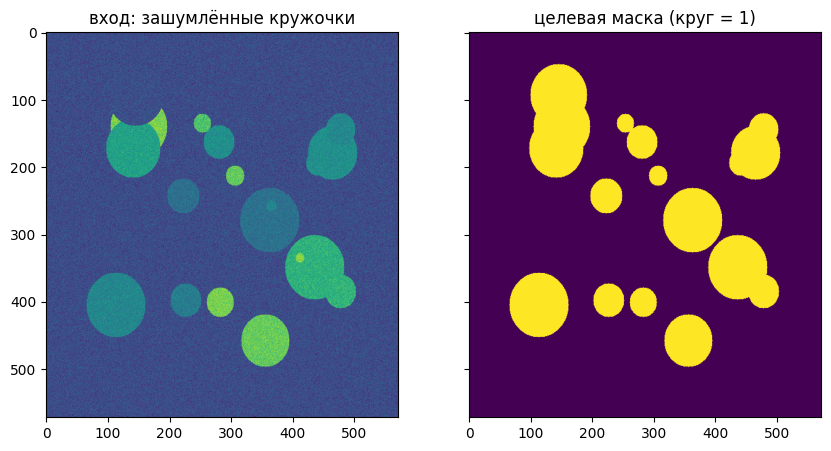

In [3]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('device:', device)

nx = 572
ny = 572
generator = GrayScaleDataProvider(nx, ny, cnt=20)

x_demo, y_demo = generator(1)
fig, ax = plt.subplots(1, 2, sharey=True, figsize=(10, 5))
ax[0].imshow(x_demo[0, ..., 0], aspect='auto')
ax[0].set_title('вход: зашумлённые кружочки')
ax[1].imshow(y_demo[0, ..., 1], aspect='auto')
ax[1].set_title('целевая маска (круг = 1)')
plt.show()

## 2. Модель: U-Net как на занятии

Архитектура с занятия 10 (`DownConv`/`UpConv`): энкодер из пяти этажей «две свёртки 3×3 + ReLU + MaxPool» сжимает картинку, пока не останется карта 36×36; декодер транспонированными свёртками поднимает разрешение обратно, и на каждом уровне к подъёму **конкатенируется** выход соответствующего этажа энкодера (skip-connection): так грубое «понимание сцены» с глубоких слоёв соединяется с точными границами с мелких. Финальная свёртка 1×1 даёт 2 канала — логиты «фон/круг» для каждого пикселя (softmax внутри `cross_entropy`).

Два практических решения:

* **Паддинг 572 → 576.** В занятии свёртки с padding=1 (размер сохраняется), но MaxPool требует делимости на 2⁴ на пути вниз: 572 → 286 → 143 → 71.5 — не делится, конкатенация skip-ов падает. Поэтому вход аккуратно дополняется reflect-паддингом до 576 (кратно 32), а предсказание срезается обратно до 572.
* **start_filts = 8.** У занятия их 64 (31 млн параметров — считали на GPU для фото кораблей). Кружочки — простая синтетика, и для обучения на CPU достаточно 8 фильтров на входе (~0.5 млн параметров); на GPU можно поставить 64 и обучить быстрее.


In [4]:
def conv1x1(in_channels, out_channels, groups=1):
    return nn.Conv2d(in_channels, out_channels, kernel_size=1, groups=groups, stride=1)


def conv3x3(in_channels, out_channels, stride=1, padding=1, bias=True, groups=1):
    return nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride,
                     padding=padding, bias=bias, groups=groups)


def upconv2x2(in_channels, out_channels, mode='transpose'):
    if mode == 'transpose':
        return nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
    return nn.Sequential(nn.Upsample(mode='bilinear', scale_factor=2),
                         conv1x1(in_channels, out_channels))


class DownConv(nn.Module):
    """Две свёртки 3×3 + ReLU; при pooling=True — MaxPool 2×2 после них."""

    def __init__(self, in_channels, out_channels, pooling=True):
        super(DownConv, self).__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.pooling = pooling

        self.conv1 = conv3x3(in_channels, out_channels)
        self.conv2 = conv3x3(out_channels, out_channels)
        if pooling:
            self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        before_pool = x
        if self.pooling:
            x = self.pool(x)
        return x, before_pool


class UpConv(nn.Module):
    """Подъём разрешения + конкатенация с выходом энкодера + две свёртки."""

    def __init__(self, in_channels, out_channels, merge_mode='concat', up_mode='transpose'):
        super(UpConv, self).__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.merge_mode = merge_mode

        self.upconv = upconv2x2(in_channels, out_channels, mode=up_mode)
        if self.merge_mode == 'concat':
            self.conv1 = conv3x3(2 * out_channels, out_channels)
        else:
            self.conv1 = conv3x3(out_channels, out_channels)
        self.conv2 = conv3x3(out_channels, out_channels)

    def forward(self, from_down, from_up):
        from_up = self.upconv(from_up)
        if self.merge_mode == 'concat':
            x = torch.cat((from_up, from_down), 1)
        else:
            x = from_up + from_down
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return x


class UNet(nn.Module):
    """U-Net (Ronneberger et al., 2015) в варианте занятия: паддинг сохраняет
    размеры, skip-connections через concat, softmax НЕ применяется —
    лосс CrossEntropy включает его сам."""

    def __init__(self, num_classes, in_channels=3, depth=5, start_filts=64,
                 up_mode='transpose', merge_mode='concat'):
        super(UNet, self).__init__()

        if up_mode not in ('transpose', 'upsample'):
            raise ValueError('"{}" is not a valid mode for upsampling'.format(up_mode))
        if merge_mode not in ('concat', 'add'):
            raise ValueError('"{}" is not a valid mode for merging'.format(merge_mode))

        self.in_channels = in_channels
        self.down_convs = []
        self.up_convs = []

        # энкодер: 5 этажей, каналы 8 -> 16 -> 32 -> 64 -> 128
        outs = 0
        for i in range(depth):
            ins = in_channels if i == 0 else outs
            outs = start_filts * (2 ** i)
            pooling = True if i < depth - 1 else False
            self.down_convs.append(DownConv(ins, outs, pooling=pooling))

        # декодер: 4 этажа подъёма, каналы обратно к start_filts
        for i in range(depth - 1):
            ins = outs
            outs = ins // 2
            self.up_convs.append(UpConv(ins, outs, up_mode=up_mode, merge_mode=merge_mode))

        self.conv_final = conv1x1(outs, num_classes)

        self.down_convs = nn.ModuleList(self.down_convs)
        self.up_convs = nn.ModuleList(self.up_convs)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.xavier_normal_(m.weight)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        encoder_outs = []
        for module in self.down_convs:
            x, before_pool = module(x)
            encoder_outs.append(before_pool)
        for i, module in enumerate(self.up_convs):
            before_pool = encoder_outs[-(i + 2)]
            x = module(before_pool, x)
        return self.conv_final(x)

In [5]:
model = UNet(num_classes=2, in_channels=1, depth=5, start_filts=8).to(device)
print('параметров:', sum(p.numel() for p in model.parameters()))

PAD = 2  # 572 + 2*PAD = 576 — кратно 2^4 по пути вниз


def forward_model(x):
    """(B,1,572,572) -> логиты (B,2,572,572). Паддинг до 576 и обратный срез."""
    xp = F.pad(x, (PAD, PAD, PAD, PAD), mode='reflect')
    out = model(xp)
    return out[:, :, PAD:-PAD, PAD:-PAD]


with torch.no_grad():
    demo = torch.tensor(x_demo, dtype=torch.float32, device=device).permute(0, 3, 1, 2)
    out = forward_model(demo)
print('вход:', tuple(demo.shape), '-> выход:', tuple(out.shape))

параметров: 485682
вход: (1, 1, 572, 572) -> выход: (1, 2, 572, 572)


## 3. Обучение

Данные бесконечны: каждый батч — свежая порция сгенерированных пар (batch = 2), так что «эпох» нет — обучаемся заданное число итераций. Оптимайзер Adam (lr = 0.001), лосс — `CrossEntropyLoss` по пикселям, как на занятии.

Контрольная пятёрка картинок генерируется заранее с отдельным seed и в обучении не участвует. Качество меряем двумя стандартными метриками сегментации: **IoU** (Жаккар: пересечение масок ÷ объединение) и **Dice** (₂·пересечение ÷ суммы площадей). Оба в [0..1], 1 — идеальное совпадение.

> ⏱ На CPU это ~20–25 минут; на GPU (Colab) — порядка пары минут.


In [6]:
# фиксированная тестовая выборка: 5 картинок с отдельным seed
np.random.seed(123)
x_test_np, y_test_np = generator(5)
x_test = torch.tensor(x_test_np, dtype=torch.float32, device=device).permute(0, 3, 1, 2)
y_test = torch.tensor(y_test_np[..., 1], dtype=torch.long, device=device)  # (5, 572, 572)


def iou_dice(preds_mask, gts_mask):
    """IoU и Dice по каждой картинке; preds/gts: (N, H, W) float 0/1."""
    inter = (preds_mask * gts_mask).sum(dim=(1, 2))
    union = ((preds_mask + gts_mask) > 0).float().sum(dim=(1, 2))
    iou = inter / (union + 1e-8)
    dice = 2 * inter / (preds_mask.sum(dim=(1, 2)) + gts_mask.sum(dim=(1, 2)) + 1e-8)
    return iou, dice


def evaluate_test():
    model.eval()
    with torch.no_grad():
        pred = forward_model(x_test).argmax(1).float()
        gt = y_test.float()
        iou, dice = iou_dice(pred, gt)
    model.train()
    return iou.mean().item(), dice.mean().item(), pred.cpu().numpy()


iou0, dice0, _ = evaluate_test()
print('До обучения:    IoU %.4f | Dice %.4f' % (iou0, dice0))

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

N_ITER = 300
CKPT_PATH = 'unet_circles_best.pth'  # лучшие веса по Dice на фиксированном тесте
history = {'loss': [], 'iou': [], 'dice': []}
best_dice = -1.0
best_iou = -1.0
best_iter = 0
start = time.time()
for it in range(1, N_ITER + 1):
    X, Y = generator(2)  # свежий батч сгенерированных пар
    x = torch.tensor(X, dtype=torch.float32, device=device).permute(0, 3, 1, 2)
    y = torch.tensor(Y[..., 1], dtype=torch.long, device=device)

    optimizer.zero_grad()
    loss = F.cross_entropy(forward_model(x), y)
    loss.backward()
    optimizer.step()
    history['loss'].append(loss.item())

    if it % 25 == 0 or it == 1:
        iou, dice, _ = evaluate_test()
        history['iou'].append(iou)
        history['dice'].append(dice)
        print('iter %3d | loss %.4f | test IoU %.4f | Dice %.4f | %4.0f sec' % (
            it, loss.item(), iou, dice, time.time() - start))
        # сохраняем снимок весов, если Dice на отложенном тесте вырос
        if dice > best_dice:
            best_dice = dice
            best_iou = iou
            best_iter = it
            torch.save(
                {
                    'model': model.state_dict(),
                    'iter': it,
                    'iou': iou,
                    'dice': dice,
                },
                CKPT_PATH,
            )
            print('  -> saved %s (iter=%d, IoU=%.4f, Dice=%.4f)' % (
                CKPT_PATH, best_iter, best_iou, best_dice))

print('Обучение заняло %.1f мин' % ((time.time() - start) / 60))
print('Лучший чекпоинт: iter=%d | IoU=%.4f | Dice=%.4f | файл=%s' % (
    best_iter, best_iou, best_dice, CKPT_PATH))

# откатываемся к лучшим весам — последняя итерация могла просесть
ckpt = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(ckpt['model'])
print('Загружены лучшие веса: iter=%d | IoU=%.4f | Dice=%.4f' % (
    ckpt['iter'], ckpt['iou'], ckpt['dice']))

До обучения:    IoU 0.0867 | Dice 0.1592
iter   1 | loss 0.7139 | test IoU 0.0192 | Dice 0.0374 |    0 sec
  -> saved unet_circles_best.pth (iter=1, IoU=0.0192, Dice=0.0374)
iter  25 | loss 0.5328 | test IoU 0.0000 | Dice 0.0000 |    4 sec
iter  50 | loss 0.2439 | test IoU 0.0000 | Dice 0.0000 |    9 sec
iter  75 | loss 0.1018 | test IoU 0.8238 | Dice 0.9017 |   12 sec
  -> saved unet_circles_best.pth (iter=75, IoU=0.8238, Dice=0.9017)
iter 100 | loss 0.1046 | test IoU 0.9046 | Dice 0.9498 |   16 sec
  -> saved unet_circles_best.pth (iter=100, IoU=0.9046, Dice=0.9498)
iter 125 | loss 0.0875 | test IoU 0.9139 | Dice 0.9549 |   20 sec
  -> saved unet_circles_best.pth (iter=125, IoU=0.9139, Dice=0.9549)
iter 150 | loss 0.2330 | test IoU 0.4898 | Dice 0.6558 |   24 sec
iter 175 | loss 0.0430 | test IoU 0.9007 | Dice 0.9472 |   27 sec
iter 200 | loss 0.0748 | test IoU 0.9205 | Dice 0.9584 |   31 sec
  -> saved unet_circles_best.pth (iter=200, IoU=0.9205, Dice=0.9584)
iter 225 | loss 0.0739 

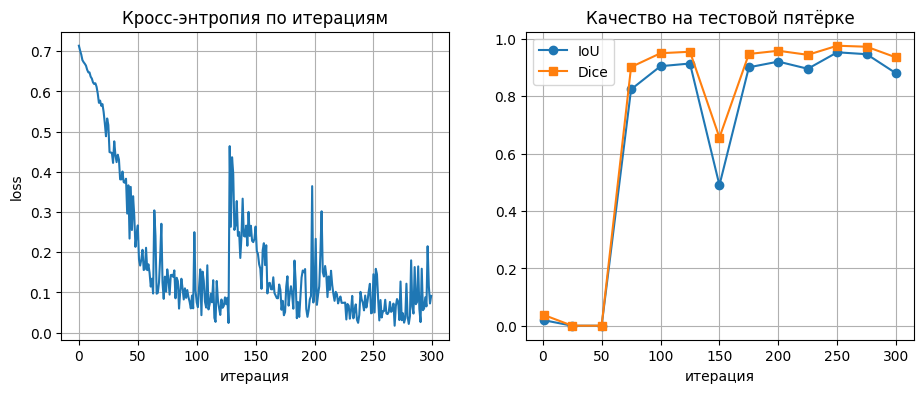

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history['loss'])
axes[0].set_title('Кросс-энтропия по итерациям')
axes[0].set_xlabel('итерация')
axes[0].set_ylabel('loss')
axes[0].grid(True)

its = ([1] + list(range(25, N_ITER + 1, 25)))[:len(history['iou'])]
axes[1].plot(its, history['iou'], 'o-', label='IoU')
axes[1].plot(its, history['dice'], 's-', label='Dice')
axes[1].set_title('Качество на тестовой пятёрке')
axes[1].set_xlabel('итерация')
axes[1].legend()
axes[1].grid(True)
plt.show()

## 4. Результаты

Финальные метрики на тестовой пятёрке и визуальное сравнение: вход, истинная маска и предсказанная маска (argmax по двум каналам).


In [8]:
# оценка на лучших весах (уже загружены в конце ячейки обучения)
model.eval()
with torch.no_grad():
    pred = forward_model(x_test).argmax(1).float()
    gt = y_test.float()
    iou_per, dice_per = iou_dice(pred, gt)

print('После обучения (best checkpoint): средние IoU %.4f | Dice %.4f' % (
    iou_per.mean().item(), dice_per.mean().item()))
print('(чекпоинт: iter=%d, IoU=%.4f, Dice=%.4f)' % (
    ckpt['iter'], ckpt['iou'], ckpt['dice']))
for i in range(pred.size(0)):
    print('  картинка %d: IoU %.4f | Dice %.4f' % (
        i + 1, iou_per[i].item(), dice_per[i].item()))

После обучения (best checkpoint): средние IoU 0.9530 | Dice 0.9759
(чекпоинт: iter=250, IoU=0.9530, Dice=0.9759)
  картинка 1: IoU 0.9551 | Dice 0.9770
  картинка 2: IoU 0.9701 | Dice 0.9848
  картинка 3: IoU 0.9516 | Dice 0.9752
  картинка 4: IoU 0.9449 | Dice 0.9717
  картинка 5: IoU 0.9432 | Dice 0.9708


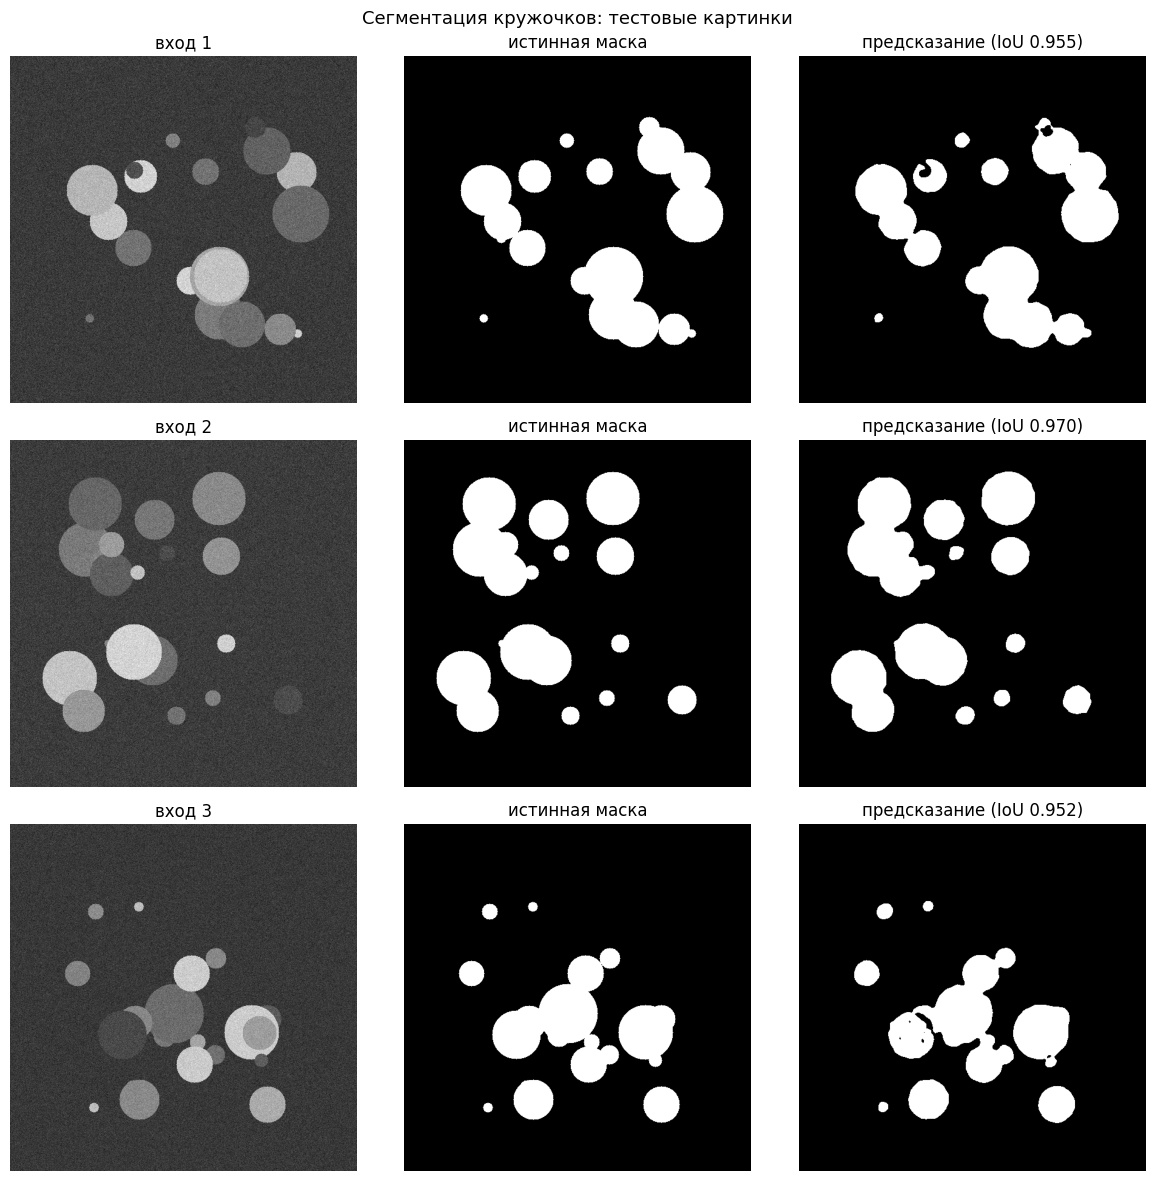

In [9]:
model.eval()
with torch.no_grad():
    preds = forward_model(x_test).argmax(1).cpu().numpy()

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    axes[i, 0].imshow(x_test_np[i, ..., 0], cmap='gray')
    axes[i, 0].set_title('вход %d' % (i + 1))
    axes[i, 1].imshow(y_test_np[i, ..., 1], cmap='gray')
    axes[i, 1].set_title('истинная маска')
    axes[i, 2].imshow(preds[i], cmap='gray')
    axes[i, 2].set_title('предсказание (IoU %.3f)' % iou_per[i].item())
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle('Сегментация кружочков: тестовые картинки', fontsize=13)
plt.tight_layout()
plt.show()

## 5. Выводы

1. Собран конвейер сегментации по заданию: генератор кружочков из `ДЗ_Лекция11.ipynb` (единственная правка — `np.bool` → `bool`, тип удалён из numpy) + U-Net с занятия 10.
2. Модель обучена на потоке синтетических пар (300 итераций, Adam, кросс-энтропия по пикселям): сначала сеть несколько десятков итераций предсказывает «одни фон» (фона по площади больше), затем быстро выходит на уверенную сегментацию (к ~250–275-й итерации IoU на тесте может превышать 0.95). В конце обучения **загружаются лучшие веса** по Dice на фиксированном тесте (`unet_circles_best.pth`) — так финальные цифры не портятся, если последняя итерация случайно просела.
3. Два инженерных решения под нашу конфигурацию: reflect-паддинг 572→576 (MaxPool-ам нужна делимость размера на 2⁴, иначе skip-конкатенация падает) и `start_filts=8` вместо 64 (для кружочков хватает; полная версия занятия обучается так же, но дольше на CPU).
4. U-Net решает задачу сегментации «в один проход»: для каждого пикселя сразу выдаётся класс, а skip-connections сохраняют точные границы кругов, которые терялись бы при сжатии в бутылочном горлышке энкодера.
